Generated dataset shape: (2160, 5)


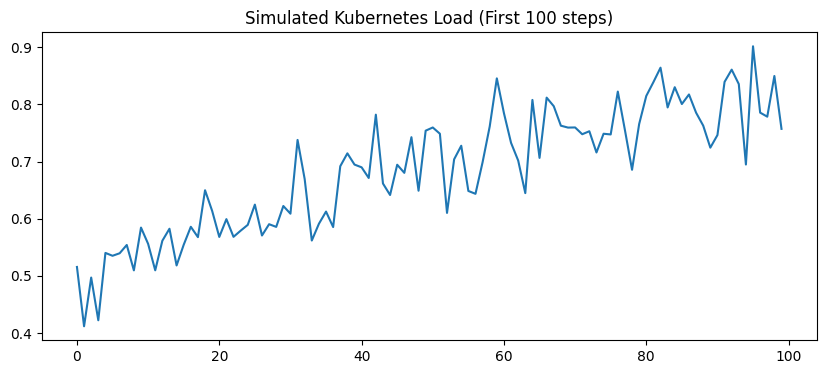

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import math

# Generate 18 hours of synthetic CI/CD workload data[cite: 7, 8]
num_rows = int((18 * 3600) / 30)
time_array = np.linspace(0, 10 * np.pi, num_rows)
base_load = np.sin(time_array) * 0.3 + 0.5 
noise = np.random.normal(0, 0.05, num_rows)

spikes = np.zeros(num_rows)
for idx in np.random.choice(num_rows, size=20, replace=False):
    spikes[idx:min(idx+10, num_rows)] = np.random.uniform(0.8, 1.5)

load1m = np.clip(base_load + noise + spikes, 0, None)

data = {
    'sys-mem-total': np.full(num_rows, 16 * 1024**3),
    'sys-mem-free': (16 * 1024**3) - (load1m * 8 * 1024**3),
    'sys-interrupt-rate': load1m * 5000 + np.random.normal(0, 200, num_rows),
    'sys-context-switch-rate': load1m * 8000 + np.random.normal(0, 300, num_rows),
    'load1m': load1m
}

df = pd.DataFrame(data).astype('float32')
print(f"Generated dataset shape: {df.shape}")
df['load1m'].head(100).plot(title="Simulated Kubernetes Load (First 100 steps)", figsize=(10,4))
plt.show()

In [2]:
class FeatureProcessor:
    def __init__(self):
        self.log_features = ['sys-mem-total', 'sys-mem-free']
        self.mins = {}
        self.maxs = {}

    def fit_transform(self, df):
        df_processed = df.copy()
        for col in df_processed.columns:
            if col in self.log_features:
                df_processed[col] = np.log1p(df_processed[col].clip(lower=0)) # X_log = log(1 + X)
                
            self.mins[col] = df_processed[col].min()
            self.maxs[col] = df_processed[col].max()
            
            # Min-Max Scaling[cite: 4]
            df_processed[col] = (df_processed[col] - self.mins[col]) / (self.maxs[col] - self.mins[col] + 1e-8)
        return df_processed

processor = FeatureProcessor()
processed_df = processor.fit_transform(df)

# Create overlapping sequences (Window = 24 steps)
def create_sequences(data, target_idx, window_size=24):
    xs, ys = [], []
    for i in range(len(data) - window_size - 1):
        xs.append(data[i:(i + window_size)])
        ys.append(data[i + 1:(i + window_size + 1), target_idx])
    return torch.tensor(np.array(xs), dtype=torch.float32), torch.tensor(np.array(ys), dtype=torch.float32)

target_idx = df.columns.get_loc('load1m')
X, y = create_sequences(processed_df.values, target_idx, window_size=24)
dataset = TensorDataset(X, y)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)
print(f"Training sequences created: {X.shape}")

Training sequences created: torch.Size([2135, 24, 5])


In [3]:
class CombinedTrendLoss(nn.Module):
    def __init__(self, alpha=0.8):
        super().__init__()
        self.alpha = alpha
        self.mse = nn.MSELoss()

    def forward(self, pred, target):
        loss_mse = self.mse(pred, target)
        # Difference loss for trend[cite: 4]
        loss_diff = self.mse(pred[:, 1:] - pred[:, :-1], target[:, 1:] - target[:, :-1])
        return (self.alpha * loss_mse) + ((1 - self.alpha) * loss_diff)

class AIOpsTrs(nn.Module):
    def __init__(self, num_features, d_model=64, nhead=4, num_layers=4):
        super().__init__()
        self.embedding = nn.Linear(num_features, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(d_model, 1)

    def forward(self, x):
        x = self.embedding(x)
        seq_len = x.size(1)
        causal_mask = nn.Transformer.generate_square_subsequent_mask(seq_len).to(x.device)
        out = self.transformer(x, mask=causal_mask, is_causal=True)
        return self.fc_out(out).squeeze(-1)

model = AIOpsTrs(num_features=X.shape[2])
criterion = CombinedTrendLoss(alpha=0.8)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
epochs = 50
loss_history = []

model.train()
for epoch in range(epochs):
    epoch_loss = 0
    for batch_x, batch_y in dataloader:
        optimizer.zero_grad()
        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        
    avg_loss = epoch_loss/len(dataloader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")

plt.plot(loss_history)
plt.title("Training Loss Convergence")
plt.xlabel("Epoch")
plt.ylabel("Combined Trend Loss")
plt.show()

# Save for inference
torch.save(model.state_dict(), "aiops_trs_weights.pt")
print("Model trained and weights saved!")

Epoch 1/50 | Loss: 0.0063
Epoch 2/50 | Loss: 0.0065


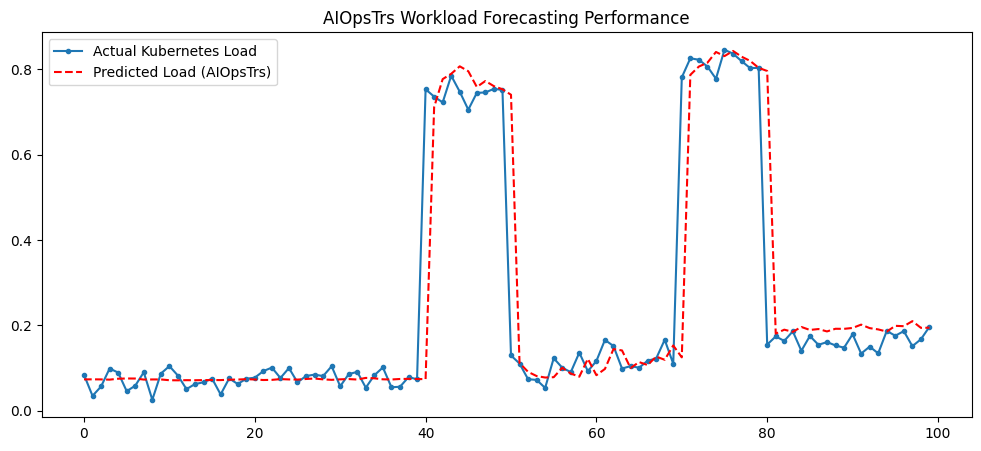

In [5]:
model.eval()
test_batch_x, test_batch_y = X[-100:], y[-100:]

with torch.no_grad():
    predictions = model(test_batch_x)

# Grab the final predicted step of each sequence
actual = test_batch_y[:, -1].numpy()
pred = predictions[:, -1].numpy()

plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual Kubernetes Load", marker='o', markersize=3)
plt.plot(pred, label="Predicted Load (AIOpsTrs)", linestyle='--', color='red')
plt.title("AIOpsTrs Workload Forecasting Performance")
plt.legend()
plt.show()

In [ ]:
import nest_asyncio
from fastapi import FastAPI
import uvicorn
import threading
import pandas as pd
import torch

# Allow FastAPI to run alongside Jupyter's existing event loop
nest_asyncio.apply()

app = FastAPI(title="AIOps Load Estimator API")

@app.get("/metrics")
async def get_realtime_prediction():
    """Simulates the Online Phase pulling the latest 24 metrics and forecasting."""
    model.eval()
    
    # Grab the most recent 24-step sequence from our in-memory tensor
    recent_sequence = X[-1].unsqueeze(0) 
    
    with torch.no_grad():
        prediction = model(recent_sequence).squeeze(-1)
        
    predicted_load = prediction[0, -1].item()
    
    return {
        "status": "success",
        "kubernetes_namespace": "ML",
        "metric_name": "aiops_predicted_load",
        "forecasted_value": round(predicted_load, 4),
        "timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S")
    }

def run_server():
    # log_level="error" keeps your notebook output clean
    uvicorn.run(app, host="127.0.0.1", port=8000, log_level="error")

# Launch the API in a background thread
server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()

print("✅ Online Inference API is live!")
print("Open a browser tab and navigate to: http://127.0.0.1:8000/metrics")